In [1]:
import matplotlib.pyplot as plt

import scipy
import torch
import os
import glob
import yaml
import json
import hashlib
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image
from pathlib import Path
from torchvision import transforms
from scipy.ndimage import gaussian_filter

from transformers import ViTConfig, ViTModel
from src.helper import (
    load_models_from_checkpoint,
    init_model_dinov3
)
from src.utils.anomaly_maps import *
from src.utils.preprocessing import *
from src.evaluation.build_anomaly_maps import get_dataset_anomaly_map_min_max

/home/vhondru/istoian/ijepa-anomaly-detection/.ijepa-venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys
print(sys.executable)

/home/vhondru/istoian/ijepa-anomaly-detection/.ijepa-venv/bin/python


In [3]:
# Set up the device
if not torch.cuda.is_available():
    device = torch.device('cpu')
else:
    device = torch.device('cuda:0')
    torch.cuda.set_device(device)

In [4]:
### Experiment config
DATASET_NAME = "BraTS2021_slice"
EXPERIMENT_NAME = "enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training"
NUM_EPOCHS = 100
WARMUP_EPOCHS = 10
TRAIN_BATCH_SIZE = 64
START_LR = 1e-6
PEAK_LR = 1e-3
FINAL_LR = 1e-5
WEIGHT_DECAY = 0.05
###

DISTANCE = "l2"
AGGREGATE_PATCHES_STRATEGY = "mean"
GAUSSIAN_FILTER_BLUR_SIGMA = 4

subpath_list = os.getcwd().split(os.sep)
root_directory_path = os.path.join(*subpath_list[:-1])
current_dir = subpath_list[-1]

EXPERIMENT_FOLDER_PATH = (
    f"/{root_directory_path}/{current_dir}/"
    f"experiments_{DATASET_NAME}/{EXPERIMENT_NAME}/checkpoints_distilled_model"
)

CONFIG_PATH = (
    f"/{root_directory_path}/{current_dir}/"
    f"experiments_{DATASET_NAME}/{EXPERIMENT_NAME}/logs/config_run.yaml"
)

CKPT_FOLDER_PATH = EXPERIMENT_FOLDER_PATH.replace(f"checkpoints_distilled_model", "checkpoints")
CKPT_FILE_PATH = f"{CKPT_FOLDER_PATH}/{EXPERIMENT_NAME}-latest.pth.tar"

distillation_config = {}
distillation_config["DATASET_NAME"] = DATASET_NAME
distillation_config["EXPERIMENT_NAME"] = EXPERIMENT_NAME
distillation_config["NUM_EPOCHS"] = NUM_EPOCHS
distillation_config["WARMUP_EPOCHS"] = WARMUP_EPOCHS
distillation_config["TRAIN_BATCH_SIZE"] = TRAIN_BATCH_SIZE
distillation_config["START_LR"] = START_LR
distillation_config["PEAK_LR"] = PEAK_LR
distillation_config["FINAL_LR"] = FINAL_LR
distillation_config["WEIGHT_DECAY"] = WEIGHT_DECAY

# Sort the dictionary by the keys
distillation_config_sorted = sorted([(field, value) for field, value in distillation_config.items()], key=lambda x: x[0], reverse=False)
print(distillation_config_sorted)

distillation_config_hash = hashlib.sha256(json.dumps(distillation_config_sorted).encode()).hexdigest()[: 16]
print(distillation_config_hash)

distillation_model_path = os.path.join(EXPERIMENT_FOLDER_PATH, f"{distillation_config_hash}_student_model.pth")

[('DATASET_NAME', 'BraTS2021_slice'), ('EXPERIMENT_NAME', 'enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training'), ('FINAL_LR', 1e-05), ('NUM_EPOCHS', 100), ('PEAK_LR', 0.001), ('START_LR', 1e-06), ('TRAIN_BATCH_SIZE', 64), ('WARMUP_EPOCHS', 10), ('WEIGHT_DECAY', 0.05)]
a5bd70b66a814550


In [5]:
with open(CONFIG_PATH, "r") as f:
    config = yaml.safe_load(f)

# Read the configuration file (which was used for training the target encoder)
# --- context encoder
encoder_model_name = config["meta"]["encoder_model_name"]
encoder_weights_path = config["meta"]["encoder_weights_source"]
encoder_embed_dim = config["meta"]["encoder_embed_dim"]

# --- target encoder
target_encoder_model_name = config["meta"]["target_encoder_model_name"]
target_encoder_weights_path = config["meta"]["target_encoder_weights_source"]

# --- predictor
predictor_depth = config["meta"]["predictor_depth"]
predictor_num_heads = config["meta"]["predictor_num_heads"]
predictor_embed_dim = config["meta"]["predictor_embed_dim"]

# --- data transforms
crop_size = config["data"]["crop_size"]
patch_size = config["mask"]["patch_size"]
count_border_pixels = config["data"]["count_border_pixels"]

# Init DinoV3/I-Jepa models: (context) encoder (DinoV3) + predictor (I-Jepa checkpoint) + target_encoder (DinoV3 - same architecture as the context encoder)
dict_models = init_model_dinov3(
    device=device,
    encoder_model_name=encoder_model_name,
    encoder_weights_path=encoder_weights_path,
    predictor_depth=predictor_depth,
    encoder_embed_dim=encoder_embed_dim,
    predictor_embed_dim=predictor_embed_dim,
    predictor_num_patches=(crop_size // patch_size) * (crop_size // patch_size),
    predictor_num_heads=predictor_num_heads,
    target_encoder_model_name=target_encoder_model_name,
    target_encoder_weights_path=target_encoder_weights_path
)
encoder = dict_models["encoder"]
predictor = dict_models["predictor"]
target_encoder = dict_models["target_encoder"]

# Load the pre-trained checkpoint (encoder + target encoder - DinoV3 VitS, predictor - IJepa checkpoint)
print(f"Loading checkpoint from: {CKPT_FILE_PATH}")
loaded_dict_from_checkpoint = load_models_from_checkpoint(
    checkpoint_path=CKPT_FILE_PATH,
    encoder=encoder,
    predictor=predictor,
    target_encoder=target_encoder,
    optimizer=None,
    scaler=None,
    dinov3_ckpt=True
)

target_encoder = loaded_dict_from_checkpoint["target_encoder"]

del loaded_dict_from_checkpoint

INFO:dinov3:using base=100 for rope new
INFO:dinov3:using min_period=None for rope new
INFO:dinov3:using max_period=None for rope new
INFO:dinov3:using normalize_coords=separate for rope new
INFO:dinov3:using shift_coords=None for rope new
INFO:dinov3:using rescale_coords=2 for rope new
INFO:dinov3:using jitter_coords=None for rope new
INFO:dinov3:using dtype=fp32 for rope new
INFO:dinov3:using mlp layer as FFN


Using cache found in /home/vhondru/.cache/torch/hub/facebookresearch_dinov3_main


INFO:root:Correctly initialized pretrained encoder (DinoV3 checkpoint)!
INFO:root:Correctly initialized pretrained predictor (to load the weights from an IJepa checkpoint)!
INFO:dinov3:using base=100 for rope new
INFO:dinov3:using min_period=None for rope new
INFO:dinov3:using max_period=None for rope new
INFO:dinov3:using normalize_coords=separate for rope new
INFO:dinov3:using shift_coords=None for rope new
INFO:dinov3:using rescale_coords=2 for rope new
INFO:dinov3:using jitter_coords=None for rope new
INFO:dinov3:using dtype=fp32 for rope new
INFO:dinov3:using mlp layer as FFN
INFO:root:Correctly initialized a pretrained target encoder (DinoV3 checkpoint)!
Loading checkpoint from: /home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training/checkpoints/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training-latest.pth.tar
INFO:root:Loading the checkpoint 

Using cache found in /home/vhondru/.cache/torch/hub/facebookresearch_dinov3_main


INFO:root:Correctly loaded pretrained encoder from epoch 20 with msg: <All keys matched successfully>
INFO:root:Correctly loaded pretrained predictor from epoch 20 with msg: <All keys matched successfully>
INFO:root:Correctly loaded pretrained target encoder from epoch 20 with msg: <All keys matched successfully>
INFO:root:Correctly loaded the weights of the models from the checkpoint saved at the path: /home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training/checkpoints/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training-latest.pth.tar


In [6]:
# Loading the trained model
configuration = ViTConfig(
    hidden_size=384,
    num_hidden_layers=6,
    num_attention_heads=6,
    intermediate_size=1536
)

student_model = ViTModel(configuration).to(device)
student_model.load_state_dict(torch.load(distillation_model_path, weights_only=True))

<All keys matched successfully>

In [7]:
normal_images_paths = sorted(glob.glob(os.path.join(f"/media/vhondru/hdd/istoian/BMAD/dataset/{DATASET_NAME}/valid/good/img/", "*.png")))
print(len(normal_images_paths))
anomaly_images_paths = sorted(glob.glob(os.path.join(f"/media/vhondru/hdd/istoian/BMAD/dataset/{DATASET_NAME}/valid/ungood/img/", "*.png")))
print(len(anomaly_images_paths))

39
44


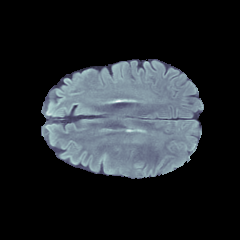

In [8]:
idx_normal_image = 10
normal_image = Image.open(normal_images_paths[idx_normal_image]).convert("RGB")
normal_image_name = Path(normal_images_paths[idx_normal_image]).stem
normal_image

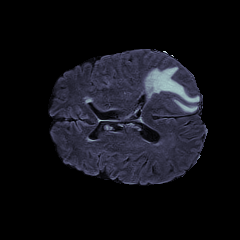

In [9]:
idx_anomaly_image = 10
anomaly_image = Image.open(anomaly_images_paths[idx_anomaly_image]).convert("RGB")
anomaly_image_name = Path(anomaly_images_paths[idx_anomaly_image]).stem
anomaly_image

In [10]:
# Load the validation dataset
image_transform = transforms.Compose([
    transforms.Resize((crop_size, crop_size), Image.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

def preprocess_image(original_image):
    # crop the background border from the image
    image_arr = np.array(original_image)

    if DATASET_NAME == "RESC":
        image_arr = remove_noise(image_arr)

    borders_dict = get_image_background_borders(image_arr=image_arr, count_border_pixels=count_border_pixels)
    image = original_image.crop(box=(borders_dict["left"], borders_dict["top"], borders_dict["right"], borders_dict["bottom"]))
    display(image)

    # apply transformations
    image = image_transform(image)
    
    return image, borders_dict


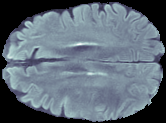

torch.Size([1, 3, 224, 224])


In [11]:
normal_tensor_preprocessed, borders_dict_normal = preprocess_image(normal_image)
normal_tensor_preprocessed = torch.unsqueeze(normal_tensor_preprocessed, dim=0).to(device)
print(normal_tensor_preprocessed.shape)

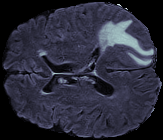

torch.Size([1, 3, 224, 224])


In [12]:
anomaly_tensor_preprocessed, borders_dict_anomaly = preprocess_image(anomaly_image)
anomaly_tensor_preprocessed = torch.unsqueeze(anomaly_tensor_preprocessed, dim=0).to(device)
print(anomaly_tensor_preprocessed.shape)

In [13]:
def compute_distances(image, image_name):
    image_per_patch_distances = {}
    # --- Target encoder (teacher) forward prop
    target_encoder_emb = target_encoder(image)
    # --- Student model forward prop
    student_emb = student_model(image).last_hidden_state[:, 1: , :]

    assert target_encoder_emb.shape == student_emb.shape

    # --- Compute the metrics
    # Average distance between the predicted and target patch-level representations (embeddings) for the random box
    if DISTANCE == "l2":
        distance_per_patch = torch.linalg.vector_norm(student_emb - target_encoder_emb, ord=2, dim=2)
    elif DISTANCE == "l1":
        distance_per_patch = torch.linalg.vector_norm(student_emb - target_encoder_emb, ord=1, dim=2)
    else:
        print("Distance metric is not correct! Set DISTANCE to one of the following options: l1, l2")
        return

    num_patches = distance_per_patch.shape[1]
    image_per_patch_distances[image_name] = {patch_idx: [] for patch_idx in range(num_patches)}
    for patch_idx in range(num_patches):
        image_per_patch_distances[image_name][patch_idx] = [distance_per_patch[0, patch_idx].item()]

    return image_per_patch_distances   

In [14]:
distance_per_patch_normal = compute_distances(normal_tensor_preprocessed, image_name=normal_image_name)

In [15]:
distance_per_patch_normal

{'00574_99': {0: [0.36182302236557007],
  1: [0.3773639500141144],
  2: [0.39157652854919434],
  3: [0.35777658224105835],
  4: [0.31059664487838745],
  5: [0.3304547071456909],
  6: [0.6218776702880859],
  7: [0.7719944715499878],
  8: [0.8045685887336731],
  9: [0.8407334685325623],
  10: [0.48467493057250977],
  11: [0.4054719805717468],
  12: [0.3640821576118469],
  13: [0.3941417932510376],
  14: [0.406194269657135],
  15: [0.39113256335258484],
  16: [0.38891369104385376],
  17: [0.6204128265380859],
  18: [0.641156792640686],
  19: [0.7406683564186096],
  20: [1.00867760181427],
  21: [0.5629074573516846],
  22: [0.792260468006134],
  23: [0.793121337890625],
  24: [0.8944641947746277],
  25: [0.7478153109550476],
  26: [0.4364047944545746],
  27: [0.426180899143219],
  28: [0.45358648896217346],
  29: [0.41344597935676575],
  30: [0.9206206202507019],
  31: [0.6413928270339966],
  32: [0.6468456983566284],
  33: [0.8516632914543152],
  34: [0.7677749395370483],
  35: [0.5692398

In [16]:
distance_per_patch_anomaly = compute_distances(anomaly_tensor_preprocessed, image_name=anomaly_image_name)

In [17]:
distance_per_patch_anomaly

{'00154_80': {0: [1.032454252243042],
  1: [0.9734584093093872],
  2: [0.9501173496246338],
  3: [0.9752331972122192],
  4: [0.8868405222892761],
  5: [0.8327651619911194],
  6: [0.710865318775177],
  7: [0.5968734622001648],
  8: [0.5838544368743896],
  9: [0.8038495779037476],
  10: [0.9704661965370178],
  11: [0.9085143804550171],
  12: [0.947457492351532],
  13: [0.8996365666389465],
  14: [1.0266122817993164],
  15: [0.9913768768310547],
  16: [0.8836902976036072],
  17: [0.8351543545722961],
  18: [0.6344340443611145],
  19: [0.580944836139679],
  20: [0.6440765857696533],
  21: [0.52589350938797],
  22: [0.6795399188995361],
  23: [0.6213449239730835],
  24: [0.45041537284851074],
  25: [0.8528311252593994],
  26: [0.985935628414154],
  27: [0.9319745898246765],
  28: [1.1364771127700806],
  29: [0.9128211140632629],
  30: [0.7470407485961914],
  31: [0.878600537776947],
  32: [0.6184148788452148],
  33: [0.6342369914054871],
  34: [0.692232072353363],
  35: [0.6473017930984497]

In [18]:
anomaly_map_normal = build_anomaly_map_with_borders(
    per_patch_distances_dict=distance_per_patch_normal[normal_image_name],
    patch_size=patch_size,
    borders_dict=borders_dict_normal,
    model_input_height=crop_size,
    model_input_width=crop_size,
    original_image_height=borders_dict_normal["original_image_height"],
    original_image_width=borders_dict_normal["original_image_width"],
    agg_strategy=AGGREGATE_PATCHES_STRATEGY,
    interpolation_method=cv2.INTER_LINEAR
)

if GAUSSIAN_FILTER_BLUR_SIGMA != -1:
    anomaly_map_normal = gaussian_filter(anomaly_map_normal, GAUSSIAN_FILTER_BLUR_SIGMA)

In [19]:
anomaly_map_anomaly= build_anomaly_map_with_borders(
    per_patch_distances_dict=distance_per_patch_anomaly[anomaly_image_name],
    patch_size=patch_size,
    borders_dict=borders_dict_anomaly,
    model_input_height=crop_size,
    model_input_width=crop_size,
    original_image_height=borders_dict_anomaly["original_image_height"],
    original_image_width=borders_dict_anomaly["original_image_width"],
    agg_strategy=AGGREGATE_PATCHES_STRATEGY,
    interpolation_method=cv2.INTER_LINEAR
)


if GAUSSIAN_FILTER_BLUR_SIGMA != -1:
    anomaly_map_anomaly = gaussian_filter(anomaly_map_anomaly, GAUSSIAN_FILTER_BLUR_SIGMA)

In [20]:
max_elem = max(anomaly_map_normal.flatten().tolist() + anomaly_map_anomaly.flatten().tolist())
min_elem = min(anomaly_map_normal.flatten().tolist() + anomaly_map_anomaly.flatten().tolist())

print(max_elem)
print(min_elem)

3.1867610230215586
0.0


In [21]:
anomaly_map_normal_scaled = (anomaly_map_normal - min_elem) / (max_elem - min_elem)
anomaly_map_anomaly_scaled = (anomaly_map_anomaly - min_elem) / (max_elem - min_elem)

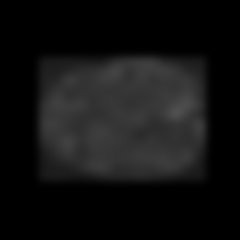

In [22]:
Image.fromarray((255 * anomaly_map_normal_scaled).astype("uint8")).convert("L")

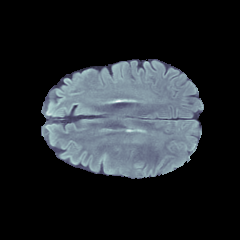

In [23]:
normal_image

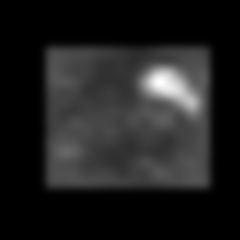

In [24]:
Image.fromarray((255 * anomaly_map_anomaly_scaled).astype("uint8")).convert("L")

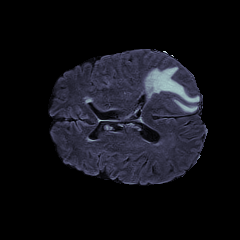

In [25]:
anomaly_image

In [26]:
anomaly_image_name

'00154_80'